In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned research papers
papers = pd.read_parquet(
    "../data/processed/embedded_papers.parquet"
)

print("Dataset shape:", papers.shape)
print("\nColumns:")
print(papers.columns.tolist())

Dataset shape: (767, 19)

Columns:
['paper_id', 'doi', 'title', 'abstract', 'year', 'publication_date', 'citation_count', 'authors', 'institutions', 'topics', 'keywords', 'referenced_works', 'related_works', 'is_open_access', 'pdf_url', 'paper_category', 'abstract_length', 'title_normalized', 'text_for_embedding']


In [3]:
# Build NLP text corpus
papers["title"] = papers["title"].fillna("")
papers["abstract"] = papers["abstract"].fillna("")

papers["text_for_nlp"] = (
    papers["title"].str.strip() + ". " +
    papers["abstract"].str.strip()
)

# Remove papers with essentially no text
papers_nlp = papers[
    papers["text_for_nlp"].str.len() > 50
].copy()

print("Original papers:", len(papers))
print("Papers available for NLP:", len(papers_nlp))
print("Removed:", len(papers) - len(papers_nlp))

print("\nExample:")
print(papers_nlp[["title", "text_for_nlp"]].iloc[0])

Original papers: 767
Papers available for NLP: 767
Removed: 0

Example:
title           A Comprehensive Overview of Large Language Models
text_for_nlp    A Comprehensive Overview of Large Language Mod...
Name: 0, dtype: str


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF configuration
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.85,
    sublinear_tf=True
)

# Transform the research corpus
tfidf_matrix = tfidf.fit_transform(
    papers_nlp["text_for_nlp"]
)

feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of terms/features:", len(feature_names))

TF-IDF matrix shape: (767, 6932)
Number of terms/features: 6932


In [5]:
# Calculate average TF-IDF score for each term
mean_tfidf = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

# Rank terms by average TF-IDF
top_indices = mean_tfidf.argsort()[::-1][:30]

top_terms = pd.DataFrame({
    "term": feature_names[top_indices],
    "mean_tfidf": mean_tfidf[top_indices]
})

print(top_terms.to_string(index=False))

                term  mean_tfidf
                 rag    0.038990
           retrieval    0.034264
            language    0.028891
          generation    0.028600
              models    0.027910
                llms    0.027278
           knowledge    0.027147
           augmented    0.026794
 retrieval augmented    0.026186
               large    0.024382
augmented generation    0.023985
               based    0.023276
      large language    0.022888
     language models    0.022814
               model    0.022390
                data    0.020741
                 llm    0.020453
         information    0.020397
               graph    0.019389
           framework    0.019171
          multimodal    0.018672
             systems    0.018021
         performance    0.017959
      generation rag    0.017216
            accuracy    0.016534
               using    0.016267
                  ai    0.016004
               tasks    0.015912
         models llms    0.014978
          

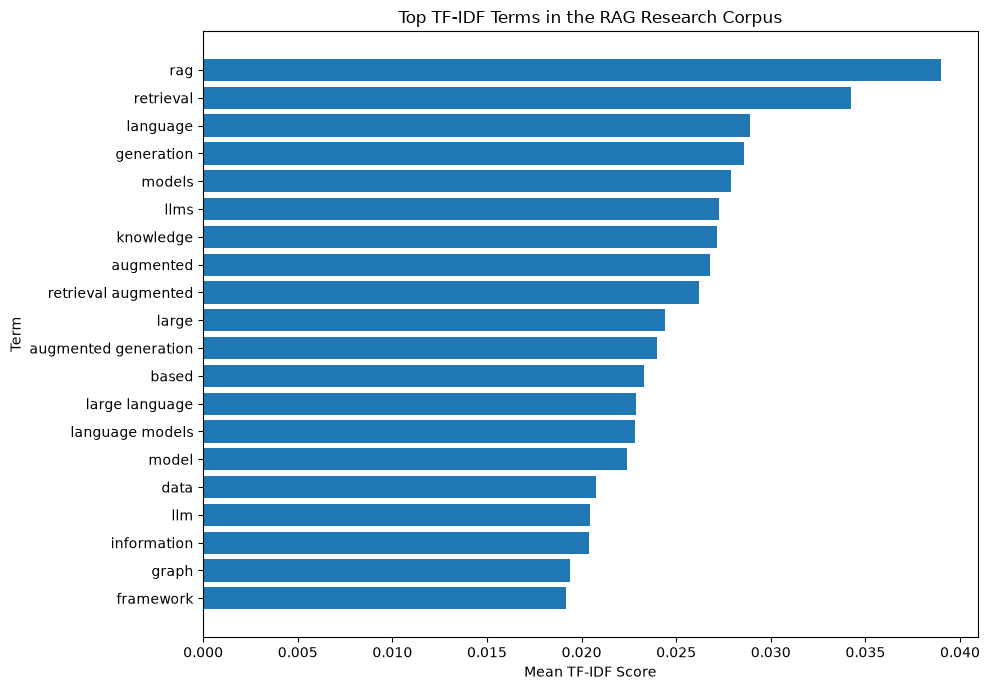

In [6]:
# Visualize the top TF-IDF terms

top_n = 20
plot_data = top_terms.head(top_n).sort_values("mean_tfidf")

plt.figure(figsize=(10, 7))
plt.barh(
    plot_data["term"],
    plot_data["mean_tfidf"]
)

plt.xlabel("Mean TF-IDF Score")
plt.ylabel("Term")
plt.title("Top TF-IDF Terms in the RAG Research Corpus")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.decomposition import NMF

# Number of latent research topics
n_topics = 10

nmf = NMF(
    n_components=n_topics,
    init="nndsvda",
    random_state=42,
    max_iter=500
)

# Learn topic representations
topic_matrix = nmf.fit_transform(tfidf_matrix)

print("Topic-document matrix shape:", topic_matrix.shape)
print("Topic-term matrix shape:", nmf.components_.shape)

Topic-document matrix shape: (767, 10)
Topic-term matrix shape: (10, 6932)


In [8]:
# Inspect the top terms for each discovered topic

n_top_words = 12

for topic_idx, topic in enumerate(nmf.components_):
    top_indices = topic.argsort()[::-1][:n_top_words]
    top_words = feature_names[top_indices]

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

Topic 1:
rag, retrieval, augmented, retrieval augmented, generation, knowledge, external, augmented generation, documents, external knowledge, llms, reasoning

Topic 2:
chapter, chapter association, linguistics human, language technologies, human language, conference, association computational, computational linguistics, technologies volume, linguistics, association, proceedings

Topic 3:
medical, clinical, healthcare, patient, health, llms, gpt, care, accuracy, study, llm, decision

Topic 4:
agent, agentic, ai, multi agent, agents, multi, rag, systems, framework, architecture, agentic rag, based

Topic 5:
multimodal, image, visual, multimodal rag, images, text, multimodal retrieval, textual, vision, rag, modal, modalities

Topic 6:
survey, research, review, llms, future, directions, comprehensive, applications, challenges, language models, models, large language

Topic 7:
2025, empirical methods, conference empirical, methods natural, language processing, conference, proceedings, proc

In [10]:
# Measure how strongly each topic appears across the corpus

topic_strength = topic_matrix.sum(axis=0)

# Assign each paper to its strongest NMF topic
dominant_topics = topic_matrix.argmax(axis=1)

# Count papers assigned to each topic
paper_counts = np.bincount(
    dominant_topics,
    minlength=n_topics
)

topic_prevalence = pd.DataFrame({
    "topic": range(1, n_topics + 1),
    "total_strength": topic_strength,
    "mean_strength": topic_matrix.mean(axis=0),
    "paper_count": paper_counts
})

topic_prevalence = topic_prevalence.sort_values(
    "total_strength",
    ascending=False
)

print(topic_prevalence.to_string(index=False))

 topic  total_strength  mean_strength  paper_count
     4       27.056250       0.035275          129
     3       24.520200       0.031969          112
     6       23.603415       0.030774           87
     8       23.183599       0.030226           94
     1       22.404162       0.029210          104
    10       20.917907       0.027272          105
     5       18.400107       0.023990           90
     7        8.883113       0.011582           15
     9        7.175338       0.009355           18
     2        6.309381       0.008226           13


In [11]:
# Assign each paper to its strongest NMF topic

papers_nlp["topic_id"] = dominant_topics + 1

# Add topic strength for the assigned topic
papers_nlp["topic_strength"] = topic_matrix.max(axis=1)

# Inspect assignments
topic_assignments = papers_nlp[
    ["paper_id", "title", "year", "topic_id", "topic_strength"]
].sort_values(
    ["topic_id", "topic_strength"],
    ascending=[True, False]
)

print(topic_assignments.head(20).to_string(index=False))

                        paper_id                                                                                                               title  year  topic_id  topic_strength
https://openalex.org/W4404781754             LongRAG: A Dual-Perspective Retrieval-Augmented Generation Paradigm for Long-Context Question Answering  2024         1        0.168214
https://openalex.org/W4412377217                                                                           Parametric Retrieval Augmented Generation  2025         1        0.164966
https://openalex.org/W4393905017                                               RQ-RAG: Learning to Refine Queries for Retrieval Augmented Generation  2024         1        0.163459
https://openalex.org/W4403560390             CRUD-RAG: A Comprehensive Chinese Benchmark for Retrieval-Augmented Generation of Large Language Models  2024         1        0.144790
https://openalex.org/W4417522321                                        Talk Before You Retriev

In [12]:
# Inspect representative papers for every discovered topic

for topic_id in range(1, n_topics + 1):
    print(f"\n{'=' * 80}")
    print(f"TOPIC {topic_id}")
    print(f"{'=' * 80}")

    topic_papers = topic_assignments[
        topic_assignments["topic_id"] == topic_id
    ].head(5)

    for _, row in topic_papers.iterrows():
        print(f"- {row['title']}")
        print(f"  Year: {row['year']} | Topic strength: {row['topic_strength']:.4f}")


TOPIC 1
- LongRAG: A Dual-Perspective Retrieval-Augmented Generation Paradigm for Long-Context Question Answering
  Year: 2024 | Topic strength: 0.1682
- Parametric Retrieval Augmented Generation
  Year: 2025 | Topic strength: 0.1650
- RQ-RAG: Learning to Refine Queries for Retrieval Augmented Generation
  Year: 2024 | Topic strength: 0.1635
- CRUD-RAG: A Comprehensive Chinese Benchmark for Retrieval-Augmented Generation of Large Language Models
  Year: 2024 | Topic strength: 0.1448
- Talk Before You Retrieve: Agent-Led Discussions for Better RAG in Medical QA
  Year: 2025 | Topic strength: 0.1440

TOPIC 2
- ARES: An Automated Evaluation Framework for Retrieval-Augmented Generation Systems
  Year: 2024 | Topic strength: 0.4511
- Adaptive-RAG: Learning to Adapt Retrieval-Augmented Large Language Models through Question Complexity
  Year: 2024 | Topic strength: 0.4413
- Can Knowledge Graphs Reduce Hallucinations in LLMs? : A Survey
  Year: 2024 | Topic strength: 0.4378
- Reducing halluc

In [13]:
# Additional corpus-specific stop words
# These terms are useful for bibliographic metadata but not research-topic discovery.

domain_stop_words = {
    "conference",
    "proceedings",
    "association",
    "annual",
    "meeting",
    "volume",
    "chapter",
    "paper",
    "papers",
    "published",
    "publication",
    "journal",
    "authors",
    "author",
    "pp",
    "pages"
}

# Combine standard English stop words with corpus-specific terms
custom_stop_words = list(
    set(tfidf.get_stop_words()).union(domain_stop_words)
)

print("Number of stop words:", len(custom_stop_words))

Number of stop words: 334


In [14]:
# Rebuild TF-IDF after removing bibliographic boilerplate

tfidf_clean = TfidfVectorizer(
    stop_words=custom_stop_words,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.85,
    sublinear_tf=True
)

tfidf_matrix_clean = tfidf_clean.fit_transform(
    papers_nlp["text_for_nlp"]
)

feature_names_clean = tfidf_clean.get_feature_names_out()

print("Clean TF-IDF matrix shape:", tfidf_matrix_clean.shape)
print("Number of features:", len(feature_names_clean))

Clean TF-IDF matrix shape: (767, 6884)
Number of features: 6884


In [15]:
# NMF on the cleaned corpus

nmf_clean = NMF(
    n_components=10,
    init="nndsvda",
    random_state=42,
    max_iter=500
)

topic_matrix_clean = nmf_clean.fit_transform(
    tfidf_matrix_clean
)

print("Clean topic-document matrix:", topic_matrix_clean.shape)
print("Clean topic-term matrix:", nmf_clean.components_.shape)

Clean topic-document matrix: (767, 10)
Clean topic-term matrix: (10, 6884)


In [16]:
# Inspect top terms from the cleaned NMF topics

n_top_words = 12

for topic_idx, topic in enumerate(nmf_clean.components_):
    top_indices = topic.argsort()[::-1][:n_top_words]
    top_words = feature_names_clean[top_indices]

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

Topic 1:
rag, information, retrieval, generation, model, augmented generation, data, study, based, retrieval augmented, using, augmented

Topic 2:
linguistics human, language technologies, human language, computational linguistics, linguistics, 2024, technologies long, computational, technologies, north, american computational, north american

Topic 3:
medical, clinical, healthcare, patient, health, decision, care, llms, clinical decision, decision support, models, gpt

Topic 4:
agent, agentic, multi agent, multi, agents, ai, agentic rag, systems, framework, rag, architecture, decision

Topic 5:
multimodal, image, visual, multimodal rag, images, text, multimodal retrieval, textual, vision, rag, modal, modalities

Topic 6:
survey, review, research, llms, future, directions, comprehensive, challenges, applications, language models, models, large language

Topic 7:
2025, computational linguistics, linguistics, li, computational, wang, zhang, language processing, xu, chen, linguistics long

In [17]:
import re

# Remove bibliographic noise from the NLP text
def clean_nlp_text(text):
    text = str(text)

    # Remove four-digit years
    text = re.sub(r"\b(19|20)\d{2}\b", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


papers_nlp["text_for_nlp_clean"] = (
    papers_nlp["text_for_nlp"]
    .apply(clean_nlp_text)
)

print(papers_nlp["text_for_nlp_clean"].iloc[0])

A Comprehensive Overview of Large Language Models. Large Language Models (LLMs) have recently demonstrated remarkable capabilities in natural language processing tasks and beyond. This success of LLMs has led to a large influx of research contributions in this direction. These works encompass diverse topics such as architectural innovations, better training strategies, context length improvements, fine-tuning, multi-modal LLMs, robotics, datasets, benchmarking, efficiency, and more. With the rapid development of techniques and regular breakthroughs in LLM research, it has become considerably challenging to perceive the bigger picture of the advances in this direction. Considering the rapidly emerging plethora of literature on LLMs, it is imperative that the research community is able to benefit from a concise yet comprehensive overview of the recent developments in this field. This article provides an overview of the existing literature on a broad range of LLM-related concepts. Our sel

In [18]:
# Final TF-IDF representation for topic modeling

tfidf_final = TfidfVectorizer(
    stop_words=custom_stop_words,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.85,
    sublinear_tf=True
)

tfidf_matrix_final = tfidf_final.fit_transform(
    papers_nlp["text_for_nlp_clean"]
)

feature_names_final = tfidf_final.get_feature_names_out()

print("Final TF-IDF matrix:", tfidf_matrix_final.shape)
print("Final number of features:", len(feature_names_final))

Final TF-IDF matrix: (767, 6866)
Final number of features: 6866


In [19]:
# Final NMF topic model

nmf_final = NMF(
    n_components=10,
    init="nndsvda",
    random_state=42,
    max_iter=500
)

topic_matrix_final = nmf_final.fit_transform(
    tfidf_matrix_final
)

print("Final topic-document matrix:", topic_matrix_final.shape)
print("Final topic-term matrix:", nmf_final.components_.shape)

Final topic-document matrix: (767, 10)
Final topic-term matrix: (10, 6866)


In [20]:
# Inspect final NMF topics

n_top_words = 12

for topic_idx, topic in enumerate(nmf_final.components_):
    top_indices = topic.argsort()[::-1][:n_top_words]
    top_words = feature_names_final[top_indices]

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

Topic 1:
rag, retrieval, generation, external, retrieval augmented, augmented, augmented generation, knowledge, llms, external knowledge, information, generation rag

Topic 2:
linguistics human, language technologies, human language, computational linguistics, linguistics, technologies long, computational, technologies, north, american computational, north american, human

Topic 3:
survey, review, research, future, llms, directions, comprehensive, applications, challenges, models, language models, techniques

Topic 4:
agent, agentic, ai, multi agent, agents, multi, rag, systems, agentic rag, architecture, framework, based

Topic 5:
multimodal, image, visual, multimodal rag, images, text, multimodal retrieval, textual, vision, rag, modal, modalities

Topic 6:
computational linguistics, linguistics, li, computational, wang, zhang, chen, xu, language processing, linguistics long, wu, processing

Topic 7:
clinical, medical, healthcare, patient, health, llms, gpt, care, decision, llm, study

In [21]:
# Final topic assignments

dominant_topics_final = topic_matrix_final.argmax(axis=1)

papers_nlp["topic_id"] = dominant_topics_final + 1
papers_nlp["topic_strength"] = topic_matrix_final.max(axis=1)

# Count papers assigned to each topic
final_topic_counts = np.bincount(
    dominant_topics_final,
    minlength=n_topics
)

topic_summary = pd.DataFrame({
    "topic_id": range(1, n_topics + 1),
    "paper_count": final_topic_counts,
    "percentage": final_topic_counts / len(papers_nlp) * 100
})

print(topic_summary.to_string(index=False))

 topic_id  paper_count  percentage
        1           86   11.212516
        2           12    1.564537
        3           78   10.169492
        4          128   16.688396
        5           87   11.342894
        6           30    3.911343
        7           92   11.994785
        8           94   12.255541
        9          101   13.168188
       10           59    7.692308


In [22]:
# Human-readable topic labels

topic_labels = {
    1: "Core RAG & Retrieval",
    2: "Computational Linguistics",
    3: "Surveys & Research Directions",
    4: "Agentic RAG & Multi-Agent Systems",
    5: "Multimodal RAG",
    6: "NLP / Computational Linguistics",
    7: "Medical & Clinical LLMs",
    8: "Graph RAG & Knowledge Graphs",
    9: "LLM Training & Fine-Tuning",
    10: "Question Answering & Retrieval"
}

topic_summary["topic_name"] = topic_summary["topic_id"].map(topic_labels)

print(
    topic_summary[
        ["topic_id", "topic_name", "paper_count", "percentage"]
    ].to_string(index=False)
)

 topic_id                        topic_name  paper_count  percentage
        1              Core RAG & Retrieval           86   11.212516
        2         Computational Linguistics           12    1.564537
        3     Surveys & Research Directions           78   10.169492
        4 Agentic RAG & Multi-Agent Systems          128   16.688396
        5                    Multimodal RAG           87   11.342894
        6   NLP / Computational Linguistics           30    3.911343
        7           Medical & Clinical LLMs           92   11.994785
        8      Graph RAG & Knowledge Graphs           94   12.255541
        9        LLM Training & Fine-Tuning          101   13.168188
       10    Question Answering & Retrieval           59    7.692308


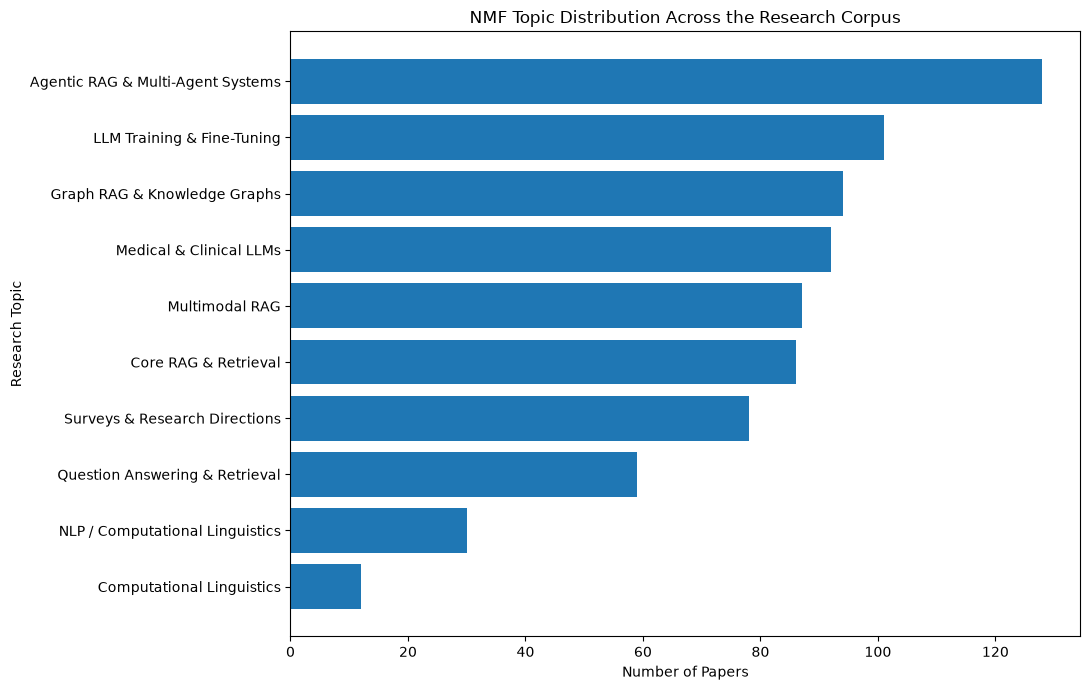

In [23]:
# Visualize topic distribution

plot_data = topic_summary.sort_values("paper_count")

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["topic_name"],
    plot_data["paper_count"]
)

plt.xlabel("Number of Papers")
plt.ylabel("Research Topic")
plt.title("NMF Topic Distribution Across the Research Corpus")

plt.tight_layout()
plt.show()

In [24]:
# Topic distribution by publication year

year_topic = pd.crosstab(
    papers_nlp["year"],
    papers_nlp["topic_id"],
    normalize="index"
) * 100

# Keep only years with data
year_topic = year_topic.sort_index()

# Rename topic columns
year_topic.columns = [
    topic_labels.get(col, f"Topic {col}")
    for col in year_topic.columns
]

print(year_topic.round(2).to_string())

      Core RAG & Retrieval  Computational Linguistics  Surveys & Research Directions  Agentic RAG & Multi-Agent Systems  Multimodal RAG  NLP / Computational Linguistics  Medical & Clinical LLMs  Graph RAG & Knowledge Graphs  LLM Training & Fine-Tuning  Question Answering & Retrieval
year                                                                                                                                                                                                                                                                                       
2020                  0.00                       0.00                          15.38                              23.08            0.00                             7.69                     0.00                         15.38                       30.77                            7.69
2021                  0.00                       8.33                           8.33                              16.67            0.00             

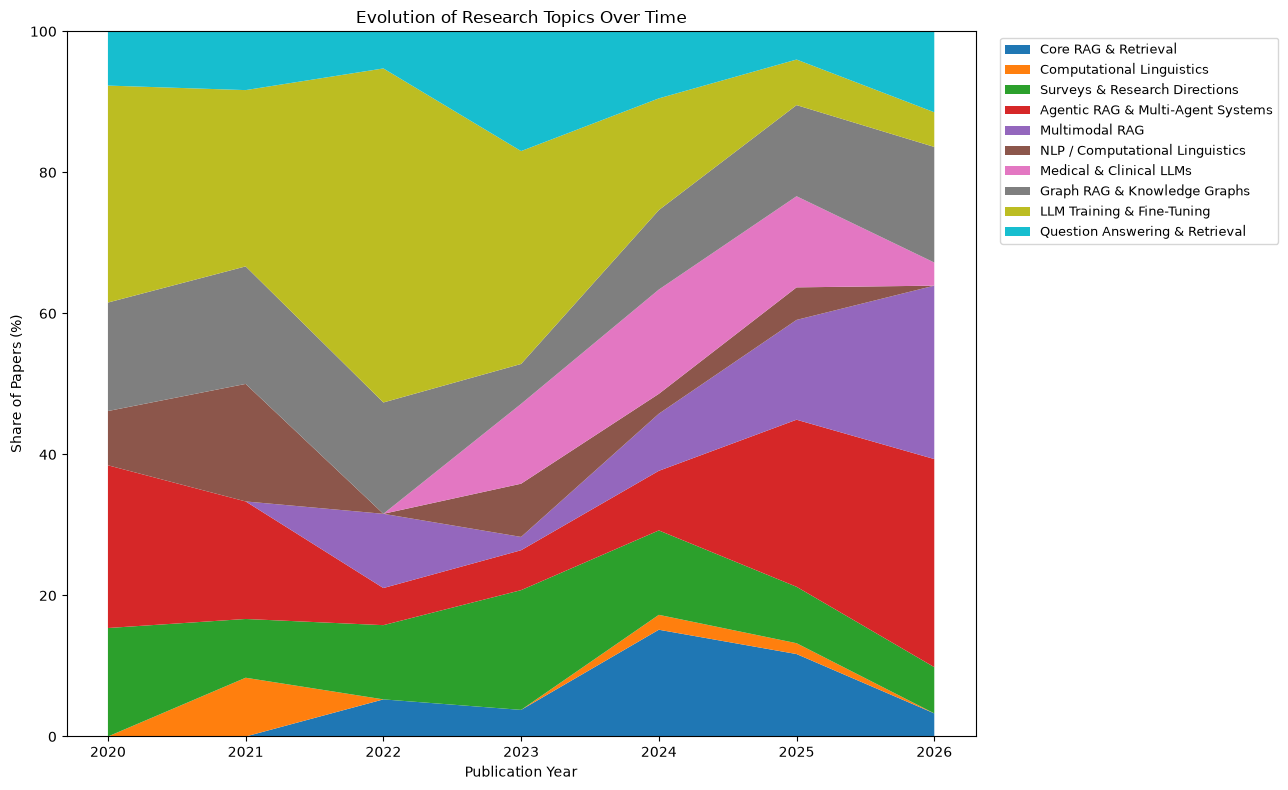

In [25]:
# Temporal evolution of research topics

plt.figure(figsize=(13, 8))

plt.stackplot(
    year_topic.index,
    *[year_topic[col] for col in year_topic.columns],
    labels=year_topic.columns
)

plt.xlabel("Publication Year")
plt.ylabel("Share of Papers (%)")
plt.title("Evolution of Research Topics Over Time")
plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

plt.xticks(year_topic.index)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Load graph community assignments
communities = pd.read_parquet(
    "../data/processed/community_assignments.parquet"
)

print("Community dataset shape:", communities.shape)
print("\nColumns:")
print(communities.columns.tolist())

Community dataset shape: (767, 5)

Columns:
['node', 'community', 'title', 'year', 'citation_count']


In [28]:
# Align NLP topics with graph communities

comparison_df = papers_nlp[
    ["paper_id", "title", "topic_id"]
].copy()

# Convert both identifiers to the same type
comparison_df["paper_id"] = comparison_df["paper_id"].astype(str)
communities["node"] = communities["node"].astype(str)

comparison_df = comparison_df.merge(
    communities[["node", "community"]],
    left_on="paper_id",
    right_on="node",
    how="inner"
)

print("Matched papers:", len(comparison_df))
print("Unmatched papers:", len(papers_nlp) - len(comparison_df))

print("\nUnique NLP topics:", comparison_df["topic_id"].nunique())
print("Unique graph communities:", comparison_df["community"].nunique())

Matched papers: 0
Unmatched papers: 767

Unique NLP topics: 0
Unique graph communities: 0


In [29]:
print("NLP paper IDs:")
print(papers_nlp["paper_id"].head(10).tolist())

print("\nGraph node IDs:")
print(communities["node"].head(10).tolist())

print("\nNLP paper_id dtype:", papers_nlp["paper_id"].dtype)
print("Graph node dtype:", communities["node"].dtype)

NLP paper IDs:
['https://openalex.org/W4384389802', 'https://openalex.org/W4390602555', 'https://openalex.org/W4403578737', 'https://openalex.org/W4407164528', 'https://openalex.org/W4416291690', 'https://openalex.org/W4404210426', 'https://openalex.org/W3158433122', 'https://openalex.org/W4416196623', 'https://openalex.org/W4402952652', 'https://openalex.org/W4411447250']

Graph node IDs:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

NLP paper_id dtype: str
Graph node dtype: str


In [30]:
# Verify that graph node IDs correspond to the same paper ordering

check_df = pd.DataFrame({
    "graph_node": communities["node"].astype(str),
    "graph_title": communities["title"].astype(str),
    "nlp_title": papers_nlp["title"].astype(str)
})

check_df["title_match"] = (
    check_df["graph_title"].str.strip()
    == check_df["nlp_title"].str.strip()
)

print("Total rows:", len(check_df))
print("Title matches:", check_df["title_match"].sum())
print("Title mismatches:", (~check_df["title_match"]).sum())

print("\nFirst 10 comparisons:")
print(
    check_df[
        ["graph_node", "graph_title", "nlp_title", "title_match"]
    ].head(10).to_string(index=False)
)

Total rows: 767
Title matches: 767
Title mismatches: 0

First 10 comparisons:
graph_node                                                                                                                                          graph_title                                                                                                                                            nlp_title  title_match
         0                                                                                                    A Comprehensive Overview of Large Language Models                                                                                                    A Comprehensive Overview of Large Language Models         True
         1                                                               A Comprehensive Survey of Hallucination Mitigation Techniques in Large Language Models                                                               A Comprehensive Survey of Hallucination Mitigation Techn

In [31]:
# Compare NLP topics with graph communities

nlp_labels = papers_nlp["topic_id"].to_numpy()
graph_labels = communities["community"].to_numpy()

ari = adjusted_rand_score(
    graph_labels,
    nlp_labels
)

nmi = normalized_mutual_info_score(
    graph_labels,
    nlp_labels
)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

Adjusted Rand Index (ARI): 0.2391
Normalized Mutual Information (NMI): 0.3934


In [33]:
# Build verified NLP-topic ↔ graph-community comparison
# The ordering was verified: 767/767 titles match.

comparison_df = pd.DataFrame({
    "title": papers_nlp["title"].values,
    "topic_id": papers_nlp["topic_id"].values,
    "community": communities["community"].values
})

print("Comparison rows:", len(comparison_df))
print("Unique NLP topics:", comparison_df["topic_id"].nunique())
print("Unique graph communities:", comparison_df["community"].nunique())

# Get the 10 largest graph communities
top_communities = (
    comparison_df["community"]
    .value_counts()
    .head(10)
    .index
)

# Topic × community counts
topic_community = pd.crosstab(
    comparison_df["topic_id"],
    comparison_df["community"]
)

# Keep the 10 largest communities
topic_community_top = topic_community[top_communities]

# Rename NLP topics
topic_community_top.index = [
    topic_labels.get(i, f"Topic {i}")
    for i in topic_community_top.index
]

print("\nTopic × top-10 community matrix:")
print(topic_community_top.to_string())

Comparison rows: 767
Unique NLP topics: 10
Unique graph communities: 124

Topic × top-10 community matrix:
community                          51  8   6   9   7   17  14  0   48  13
Core RAG & Retrieval               49   5   9   8   3   3   4   0   0   0
Computational Linguistics           0   2   0   0   0   8   0   0   0   0
Surveys & Research Directions      19   6   7  11   2   8   5   8   0   3
Agentic RAG & Multi-Agent Systems   8   1  14  55   1   0   4   0   2   1
Multimodal RAG                      0   6   0   0  63   0   0   1   1   0
NLP / Computational Linguistics     1   2   2   2   2  14   0   1   0   0
Medical & Clinical LLMs             1  76   2   6   0   0   1   0   0   0
Graph RAG & Knowledge Graphs        5   7  51   4   2   0   4   0   1   0
LLM Training & Fine-Tuning         43   8   6   7   3   0   3  10   2   2
Question Answering & Retrieval     30  11   8   5   1   0   1   0   1   0


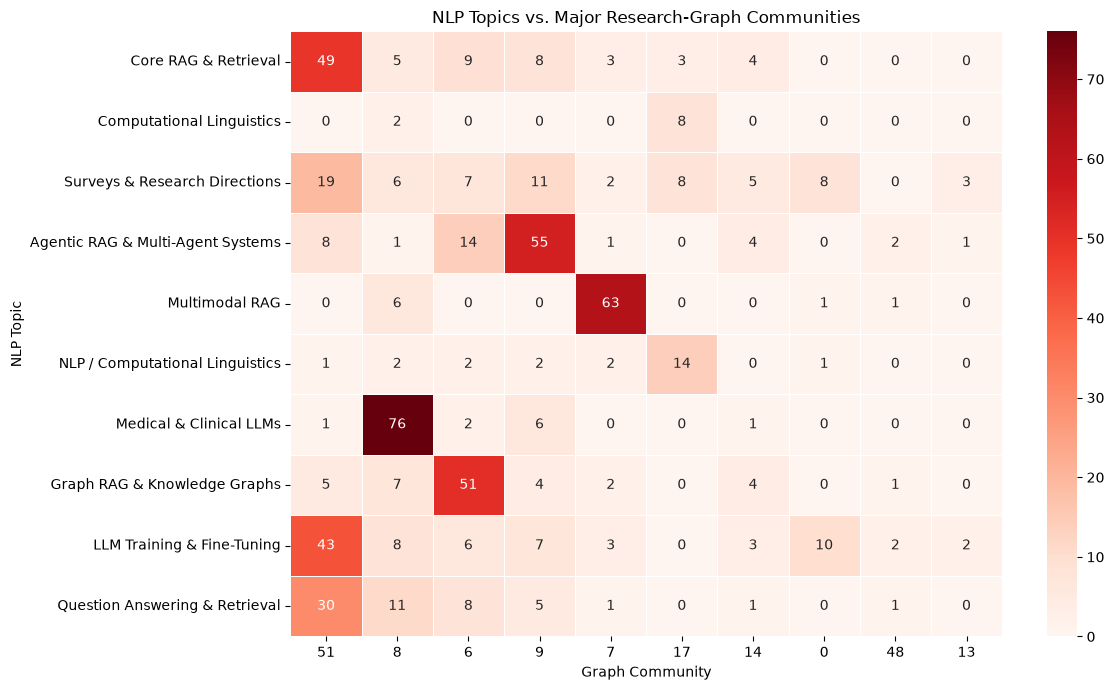

In [36]:
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.heatmap(
    topic_community_top,
    annot=True,
    fmt="d",
    cmap="Reds",
    linewidths=0.5
)

plt.xlabel("Graph Community")
plt.ylabel("NLP Topic")
plt.title("NLP Topics vs. Major Research-Graph Communities")

plt.tight_layout()
plt.show()

In [37]:
# Add citation counts to the NLP topic assignments

citation_analysis = papers_nlp[
    ["paper_id", "title", "year", "citation_count", "topic_id"]
].copy()

citation_analysis["topic_name"] = (
    citation_analysis["topic_id"].map(topic_labels)
)

# Summary statistics by topic
topic_citations = (
    citation_analysis
    .groupby(["topic_id", "topic_name"])["citation_count"]
    .agg(
        paper_count="count",
        mean_citations="mean",
        median_citations="median",
        max_citations="max"
    )
    .sort_values("median_citations", ascending=False)
)

print(topic_citations.round(2).to_string())

                                            paper_count  mean_citations  median_citations  max_citations
topic_id topic_name                                                                                     
3        Surveys & Research Directions               78          728.88             117.0          39949
2        Computational Linguistics                   12          124.92              99.0            487
7        Medical & Clinical LLMs                     92          152.24              46.0           3909
6        NLP / Computational Linguistics             30          206.47              34.5           3352
9        LLM Training & Fine-Tuning                 101          173.74              29.0           3868
10       Question Answering & Retrieval              59           97.37              27.0           1333
1        Core RAG & Retrieval                        86           32.05              17.0            382
8        Graph RAG & Knowledge Graphs                94

/var/folders/s8/56wydsq561vgvpmmr5q8y7qm0000gn/T/ipykernel_40464/3159060167.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


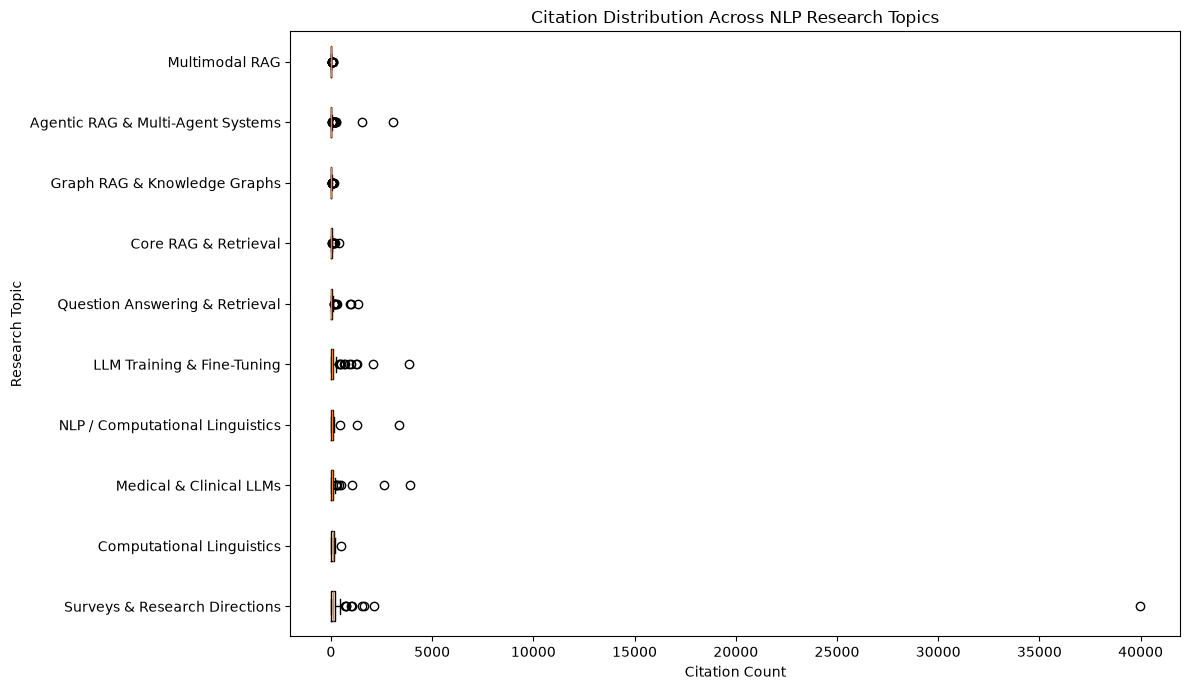

In [38]:
# Citation distribution by NLP topic

plt.figure(figsize=(12, 7))

plot_data = citation_analysis.copy()

# Keep topic order based on median citations
topic_order = (
    topic_citations
    .sort_values("median_citations", ascending=False)
    .index
)

plot_data["topic_name"] = pd.Categorical(
    plot_data["topic_name"],
    categories=[name for _, name in topic_order],
    ordered=True
)

plt.boxplot(
    [
        plot_data.loc[
            plot_data["topic_name"] == name,
            "citation_count"
        ]
        for _, name in topic_order
    ],
    tick_labels=[name for _, name in topic_order],
    vert=False
)

plt.xlabel("Citation Count")
plt.ylabel("Research Topic")
plt.title("Citation Distribution Across NLP Research Topics")
plt.tight_layout()
plt.show()

/var/folders/s8/56wydsq561vgvpmmr5q8y7qm0000gn/T/ipykernel_40464/1543003969.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


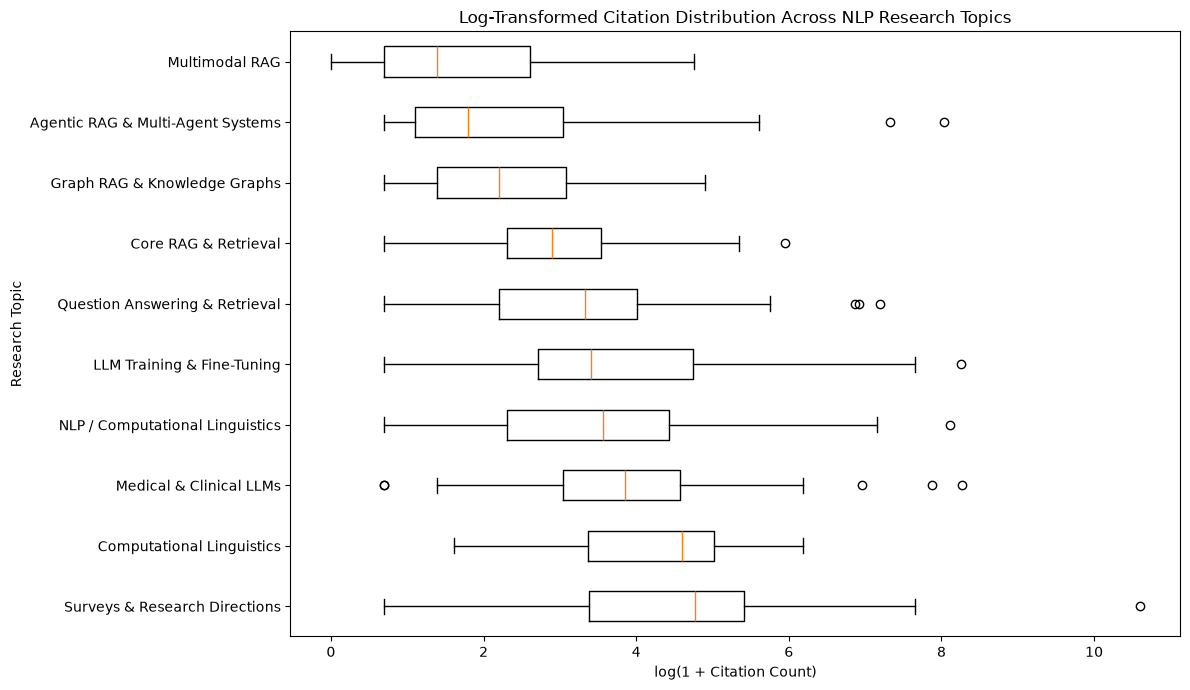

In [40]:
# Log-scale citation distribution

plot_data = papers_nlp[[
    "topic_id",
    "citation_count"
]].copy()

# Add readable topic names
plot_data["topic_name"] = plot_data["topic_id"].map(topic_labels)

# Order topics by median citation count
topic_order = (
    plot_data
    .groupby("topic_name")["citation_count"]
    .median()
    .sort_values(ascending=False)
    .index
)

citation_groups = [
    np.log1p(
        plot_data.loc[
            plot_data["topic_name"] == topic,
            "citation_count"
        ]
    )
    for topic in topic_order
]

plt.figure(figsize=(12, 7))

plt.boxplot(
    citation_groups,
    tick_labels=topic_order,
    vert=False
)

plt.xlabel("log(1 + Citation Count)")
plt.ylabel("Research Topic")
plt.title("Log-Transformed Citation Distribution Across NLP Research Topics")

plt.tight_layout()
plt.show()

In [41]:
from scipy.stats import kruskal

# Prepare citation groups for each topic
citation_groups_raw = [
    papers_nlp.loc[
        papers_nlp["topic_id"] == topic_id,
        "citation_count"
    ].dropna()
    for topic_id in sorted(papers_nlp["topic_id"].unique())
]

# Kruskal-Wallis H test
h_stat, p_value = kruskal(*citation_groups_raw)

print("Kruskal-Wallis H statistic:", round(h_stat, 4))
print("p-value:", f"{p_value:.6e}")

Kruskal-Wallis H statistic: 208.6393
p-value: 5.103381e-40


In [42]:
# Citation count vs. graph centrality

centrality = pd.read_parquet(
    "../data/processed/paper_centrality.parquet"
)

print("Centrality dataset shape:", centrality.shape)
print(centrality.columns.tolist())

Centrality dataset shape: (767, 8)
['node', 'degree_centrality', 'betweenness_centrality', 'pagerank', 'title', 'year', 'citation_count', 'community']


In [43]:
from scipy.stats import spearmanr

# Citation count vs. network centrality

metrics = [
    "degree_centrality",
    "betweenness_centrality",
    "pagerank"
]

for metric in metrics:
    valid = centrality[["citation_count", metric]].dropna()

    rho, p_value = spearmanr(
        valid["citation_count"],
        valid[metric]
    )

    print(f"{metric}")
    print(f"  Spearman rho: {rho:.4f}")
    print(f"  p-value: {p_value:.6e}")
    print()

degree_centrality
  Spearman rho: 0.0370
  p-value: 3.056360e-01

betweenness_centrality
  Spearman rho: 0.0382
  p-value: 2.907758e-01

pagerank
  Spearman rho: 0.0582
  p-value: 1.075733e-01



In [44]:
# Save final NLP analysis dataset

output_columns = [
    "paper_id",
    "title",
    "year",
    "citation_count",
    "topic_id"
]

nlp_results = papers_nlp[output_columns].copy()

nlp_results["topic_name"] = nlp_results["topic_id"].map(topic_labels)

nlp_results.to_parquet(
    "../data/processed/paper_nlp_topics.parquet",
    index=False
)

print("Saved NLP topic assignments.")
print("Shape:", nlp_results.shape)
print("\nColumns:")
print(nlp_results.columns.tolist())

Saved NLP topic assignments.
Shape: (767, 6)

Columns:
['paper_id', 'title', 'year', 'citation_count', 'topic_id', 'topic_name']


In [48]:
# Build integrated research dataset using verified paper titles

centrality_clean = centrality[
    [
        "title",
        "degree_centrality",
        "betweenness_centrality",
        "pagerank",
        "community"
    ]
].copy()

# Merge NLP analysis with graph analysis using verified exact titles
integrated_df = nlp_results.merge(
    centrality_clean,
    on="title",
    how="inner"
)

print("Integrated dataset shape:", integrated_df.shape)

print("\nColumns:")
print(integrated_df.columns.tolist())

print("\nMissing values:")
print(integrated_df.isna().sum())

print("\nDuplicate titles after merge:",
      integrated_df["title"].duplicated().sum())

Integrated dataset shape: (767, 10)

Columns:
['paper_id', 'title', 'year', 'citation_count', 'topic_id', 'topic_name', 'degree_centrality', 'betweenness_centrality', 'pagerank', 'community']

Missing values:
paper_id                  0
title                     0
year                      0
citation_count            0
topic_id                  0
topic_name                0
degree_centrality         0
betweenness_centrality    0
pagerank                  0
community                 0
dtype: int64

Duplicate titles after merge: 0


In [49]:
# Save integrated research dataset

integrated_path = "../data/processed/research_analysis_dataset.parquet"

integrated_df.to_parquet(
    integrated_path,
    index=False
)

print("Saved integrated dataset:")
print(integrated_path)
print("Shape:", integrated_df.shape)

Saved integrated dataset:
../data/processed/research_analysis_dataset.parquet
Shape: (767, 10)


In [50]:
# Topic-level network and citation summary

topic_network_summary = (
    integrated_df
    .groupby("topic_name")
    .agg(
        paper_count=("paper_id", "count"),
        median_citations=("citation_count", "median"),
        mean_degree=("degree_centrality", "mean"),
        mean_betweenness=("betweenness_centrality", "mean"),
        mean_pagerank=("pagerank", "mean")
    )
    .sort_values("paper_count", ascending=False)
)

print(topic_network_summary.round(6).to_string())

                                   paper_count  median_citations  mean_degree  mean_betweenness  mean_pagerank
topic_name                                                                                                    
Agentic RAG & Multi-Agent Systems          128               5.0     0.016941          0.001781       0.000881
LLM Training & Fine-Tuning                 101              29.0     0.029858          0.001196       0.001094
Graph RAG & Knowledge Graphs                94               8.0     0.038553          0.001432       0.001270
Medical & Clinical LLMs                     92              46.0     0.034042          0.001589       0.001261
Multimodal RAG                              87               3.0     0.029141          0.001522       0.001197
Core RAG & Retrieval                        86              17.0     0.071771          0.002493       0.001993
Surveys & Research Directions               78             117.0     0.043617          0.002722       0.001548
Q

In [51]:
# Citation analysis controlling for publication year

topic_year_stats = (
    integrated_df
    .groupby(["year", "topic_name"])
    .agg(
        paper_count=("paper_id", "count"),
        median_citations=("citation_count", "median"),
        mean_citations=("citation_count", "mean")
    )
    .reset_index()
)

print(topic_year_stats.to_string(index=False))

 year                        topic_name  paper_count  median_citations  mean_citations
 2020 Agentic RAG & Multi-Agent Systems            3            1513.0     1540.333333
 2020      Graph RAG & Knowledge Graphs            2              66.5       66.500000
 2020        LLM Training & Fine-Tuning            4             290.5      453.750000
 2020   NLP / Computational Linguistics            1            3352.0     3352.000000
 2020    Question Answering & Retrieval            1              64.0       64.000000
 2020     Surveys & Research Directions            2           20076.5    20076.500000
 2021 Agentic RAG & Multi-Agent Systems            2             203.5      203.500000
 2021         Computational Linguistics            1             139.0      139.000000
 2021      Graph RAG & Knowledge Graphs            2              12.5       12.500000
 2021        LLM Training & Fine-Tuning            3              29.0       58.333333
 2021   NLP / Computational Linguistics    

In [52]:
# Year-normalized citation analysis

integrated_df["year_median_citations"] = (
    integrated_df
    .groupby("year")["citation_count"]
    .transform("median")
)

integrated_df["relative_citations"] = (
    integrated_df["citation_count"]
    / (integrated_df["year_median_citations"] + 1)
)

topic_normalized_citations = (
    integrated_df
    .groupby("topic_name")
    .agg(
        paper_count=("paper_id", "count"),
        median_relative_citations=("relative_citations", "median"),
        mean_relative_citations=("relative_citations", "mean")
    )
    .sort_values(
        "median_relative_citations",
        ascending=False
    )
)

print(
    topic_normalized_citations.round(3).to_string()
)

                                   paper_count  median_relative_citations  mean_relative_citations
topic_name                                                                                        
Surveys & Research Directions               78                      4.032                   20.094
Computational Linguistics                   12                      3.194                    4.437
Medical & Clinical LLMs                     92                      1.968                    4.968
NLP / Computational Linguistics             30                      1.538                    2.709
LLM Training & Fine-Tuning                 101                      1.000                    2.706
Core RAG & Retrieval                        86                      0.903                    1.610
Question Answering & Retrieval              59                      0.871                    4.018
Agentic RAG & Multi-Agent Systems          128                      0.500                    1.550
Graph RAG 

In [55]:
# Validate NLP topics using top TF-IDF terms

topic_keywords = {}

for topic_id in sorted(papers_nlp["topic_id"].unique()):
    # Papers belonging to this topic
    topic_mask = papers_nlp["topic_id"].to_numpy() == topic_id

    # Average TF-IDF score for each term within the topic
    topic_scores = tfidf_matrix_final[topic_mask].mean(axis=0)

    # Get top 10 terms
    top_indices = np.asarray(topic_scores).ravel().argsort()[::-1][:10]

    terms = np.array(feature_names_final)[top_indices]

    topic_keywords[topic_id] = terms.tolist()

# Display top terms for every topic
for topic_id, terms in topic_keywords.items():
    print(f"\nTopic {topic_id}:")
    print(", ".join(terms))


Topic 1:
rag, retrieval, llms, generation, retrieval augmented, augmented, knowledge, augmented generation, models, language

Topic 2:
linguistics human, human language, language technologies, computational linguistics, linguistics, technologies long, computational, technologies, american computational, north american

Topic 3:
survey, review, llms, research, directions, models, future, language, language models, challenges

Topic 4:
agent, ai, rag, agentic, agents, multi, multi agent, based, retrieval, framework

Topic 5:
multimodal, visual, multimodal rag, image, rag, images, text, retrieval, multimodal retrieval, generation

Topic 6:
computational linguistics, linguistics, computational, li, wang, zhang, chen, xu, language processing, linguistics long

Topic 7:
clinical, medical, llms, healthcare, rag, models, health, llm, patient, language

Topic 8:
graph, knowledge, knowledge graph, rag, graphs, based, knowledge graphs, retrieval, graph based, kg

Topic 9:
model, language, models

In [56]:
# Topic coherence proxy using average pairwise cosine similarity
# between the top TF-IDF terms of each topic

from sklearn.metrics.pairwise import cosine_similarity

topic_coherence = []

for topic_id, terms in topic_keywords.items():
    term_indices = [
        np.where(feature_names_final == term)[0][0]
        for term in terms
        if term in feature_names_final
    ]

    if len(term_indices) > 1:
        term_vectors = tfidf_matrix_final[:, term_indices].T
        similarity_matrix = cosine_similarity(term_vectors)

        upper_triangle = similarity_matrix[
            np.triu_indices_from(similarity_matrix, k=1)
        ]

        coherence = upper_triangle.mean()
    else:
        coherence = np.nan

    topic_coherence.append({
        "topic_id": topic_id,
        "topic_name": topic_labels.get(topic_id, f"Topic {topic_id}"),
        "coherence": coherence
    })

coherence_df = pd.DataFrame(topic_coherence)

print(coherence_df.sort_values("coherence", ascending=False).round(3).to_string(index=False))

 topic_id                        topic_name  coherence
        1              Core RAG & Retrieval      0.704
        2         Computational Linguistics      0.643
        9        LLM Training & Fine-Tuning      0.485
       10    Question Answering & Retrieval      0.479
        3     Surveys & Research Directions      0.414
        8      Graph RAG & Knowledge Graphs      0.380
        4 Agentic RAG & Multi-Agent Systems      0.357
        6   NLP / Computational Linguistics      0.353
        5                    Multimodal RAG      0.336
        7           Medical & Clinical LLMs      0.333


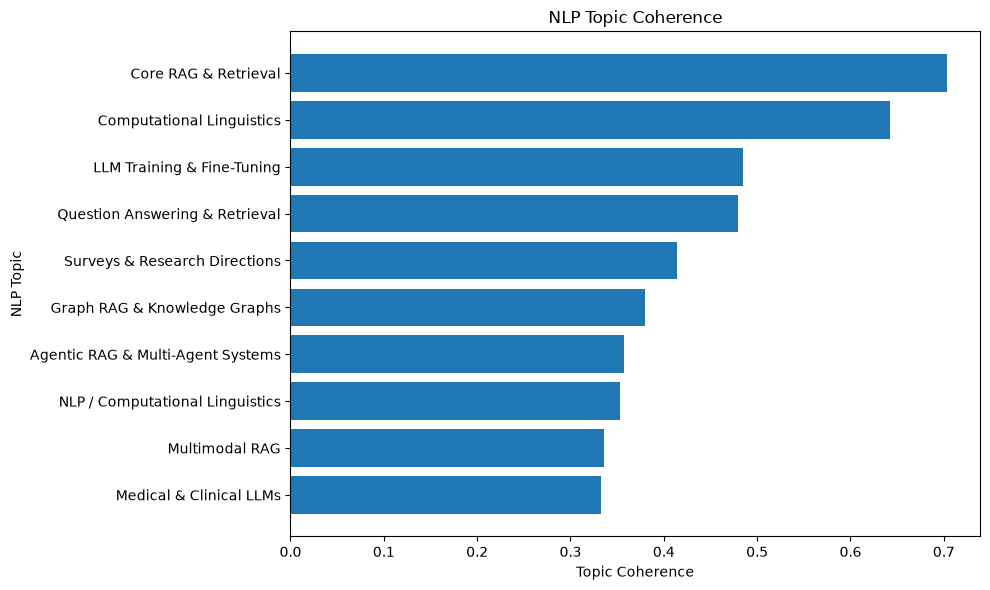

In [57]:
# Topic coherence visualization

coherence_plot = coherence_df.sort_values(
    "coherence",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    coherence_plot["topic_name"],
    coherence_plot["coherence"]
)

plt.xlabel("Topic Coherence")
plt.ylabel("NLP Topic")
plt.title("NLP Topic Coherence")

plt.tight_layout()
plt.show()

In [58]:
# NLP topic ↔ graph community alignment

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Use the integrated dataset containing both assignments
topic_ids = integrated_df["topic_id"]
community_ids = integrated_df["community"]

ari = adjusted_rand_score(topic_ids, community_ids)
nmi = normalized_mutual_info_score(topic_ids, community_ids)

print("NLP topic ↔ graph community alignment")
print("--------------------------------------")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

NLP topic ↔ graph community alignment
--------------------------------------
Adjusted Rand Index (ARI): 0.2391
Normalized Mutual Information (NMI): 0.3934


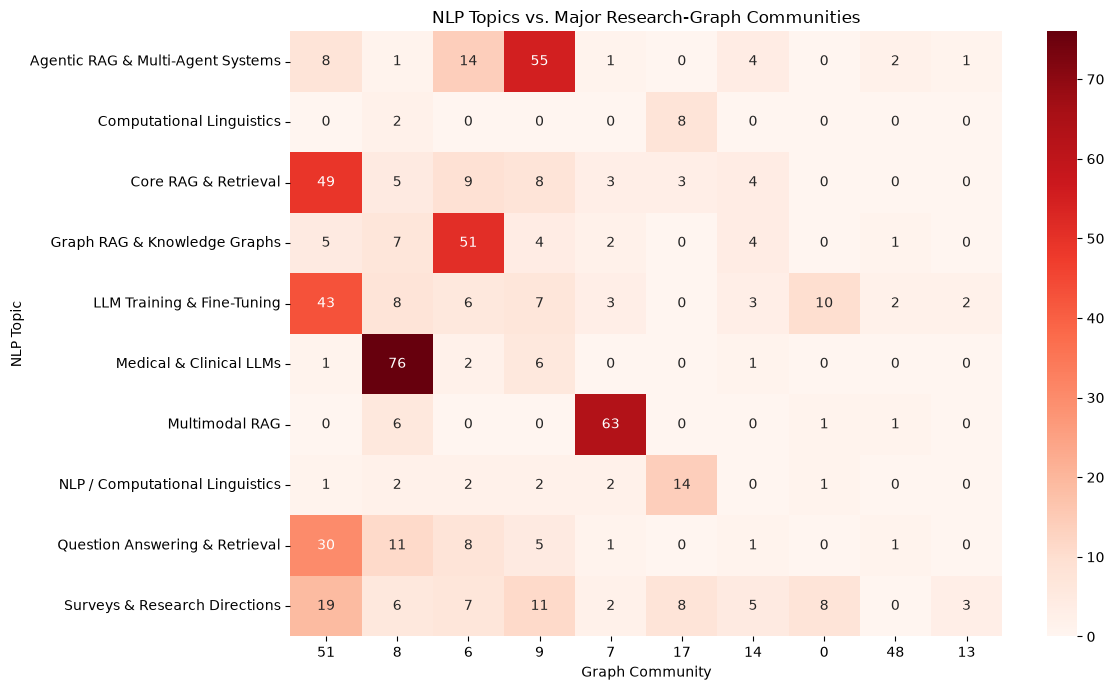

In [59]:
# NLP topic × graph community contingency matrix

topic_community_matrix = pd.crosstab(
    integrated_df["topic_name"],
    integrated_df["community"]
)

# Keep the 10 largest graph communities
major_communities = (
    integrated_df["community"]
    .value_counts()
    .head(10)
    .index
)

topic_community_top = topic_community_matrix[
    major_communities
]

plt.figure(figsize=(12, 7))

import seaborn as sns

sns.heatmap(
    topic_community_top,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title("NLP Topics vs. Major Research-Graph Communities")
plt.xlabel("Graph Community")
plt.ylabel("NLP Topic")

plt.tight_layout()
plt.show()

In [60]:
# Dominant graph community for each NLP topic

dominant_community = topic_community_matrix.idxmax(axis=1)
dominant_count = topic_community_matrix.max(axis=1)
topic_total = topic_community_matrix.sum(axis=1)

topic_alignment = pd.DataFrame({
    "topic_name": topic_community_matrix.index,
    "dominant_community": dominant_community.values,
    "papers_in_dominant_community": dominant_count.values,
    "total_papers": topic_total.values,
})

topic_alignment["dominant_share"] = (
    topic_alignment["papers_in_dominant_community"]
    / topic_alignment["total_papers"]
)

topic_alignment = topic_alignment.sort_values(
    "dominant_share",
    ascending=False
)

print(
    topic_alignment.round(3).to_string(index=False)
)

                       topic_name  dominant_community  papers_in_dominant_community  total_papers  dominant_share
          Medical & Clinical LLMs                   8                            76            92           0.826
                   Multimodal RAG                   7                            63            87           0.724
        Computational Linguistics                  17                             8            12           0.667
             Core RAG & Retrieval                  51                            49            86           0.570
     Graph RAG & Knowledge Graphs                   6                            51            94           0.543
   Question Answering & Retrieval                  51                            30            59           0.508
  NLP / Computational Linguistics                  17                            14            30           0.467
Agentic RAG & Multi-Agent Systems                   9                            55     

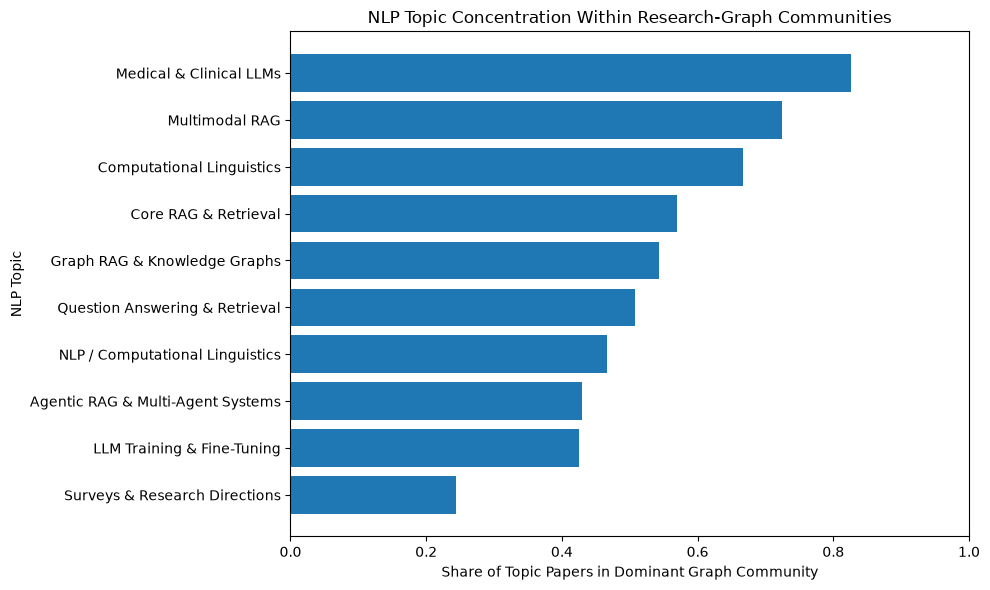

In [61]:
# Dominant graph-community concentration by NLP topic

plot_df = topic_alignment.sort_values(
    "dominant_share",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["topic_name"],
    plot_df["dominant_share"]
)

plt.xlabel("Share of Topic Papers in Dominant Graph Community")
plt.ylabel("NLP Topic")
plt.title("NLP Topic Concentration Within Research-Graph Communities")

plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [62]:
# Topic prevalence over time

topic_year_counts = (
    integrated_df
    .groupby(["year", "topic_name"])
    .size()
    .reset_index(name="paper_count")
)

# Convert counts into yearly topic proportions
year_totals = (
    integrated_df
    .groupby("year")
    .size()
    .reset_index(name="total_papers")
)

topic_year_counts = topic_year_counts.merge(
    year_totals,
    on="year"
)

topic_year_counts["topic_share"] = (
    topic_year_counts["paper_count"]
    / topic_year_counts["total_papers"]
)

print(topic_year_counts.head(15).round(3).to_string(index=False))

 year                        topic_name  paper_count  total_papers  topic_share
 2020 Agentic RAG & Multi-Agent Systems            3            13        0.231
 2020      Graph RAG & Knowledge Graphs            2            13        0.154
 2020        LLM Training & Fine-Tuning            4            13        0.308
 2020   NLP / Computational Linguistics            1            13        0.077
 2020    Question Answering & Retrieval            1            13        0.077
 2020     Surveys & Research Directions            2            13        0.154
 2021 Agentic RAG & Multi-Agent Systems            2            12        0.167
 2021         Computational Linguistics            1            12        0.083
 2021      Graph RAG & Knowledge Graphs            2            12        0.167
 2021        LLM Training & Fine-Tuning            3            12        0.250
 2021   NLP / Computational Linguistics            2            12        0.167
 2021    Question Answering & Retrieval 

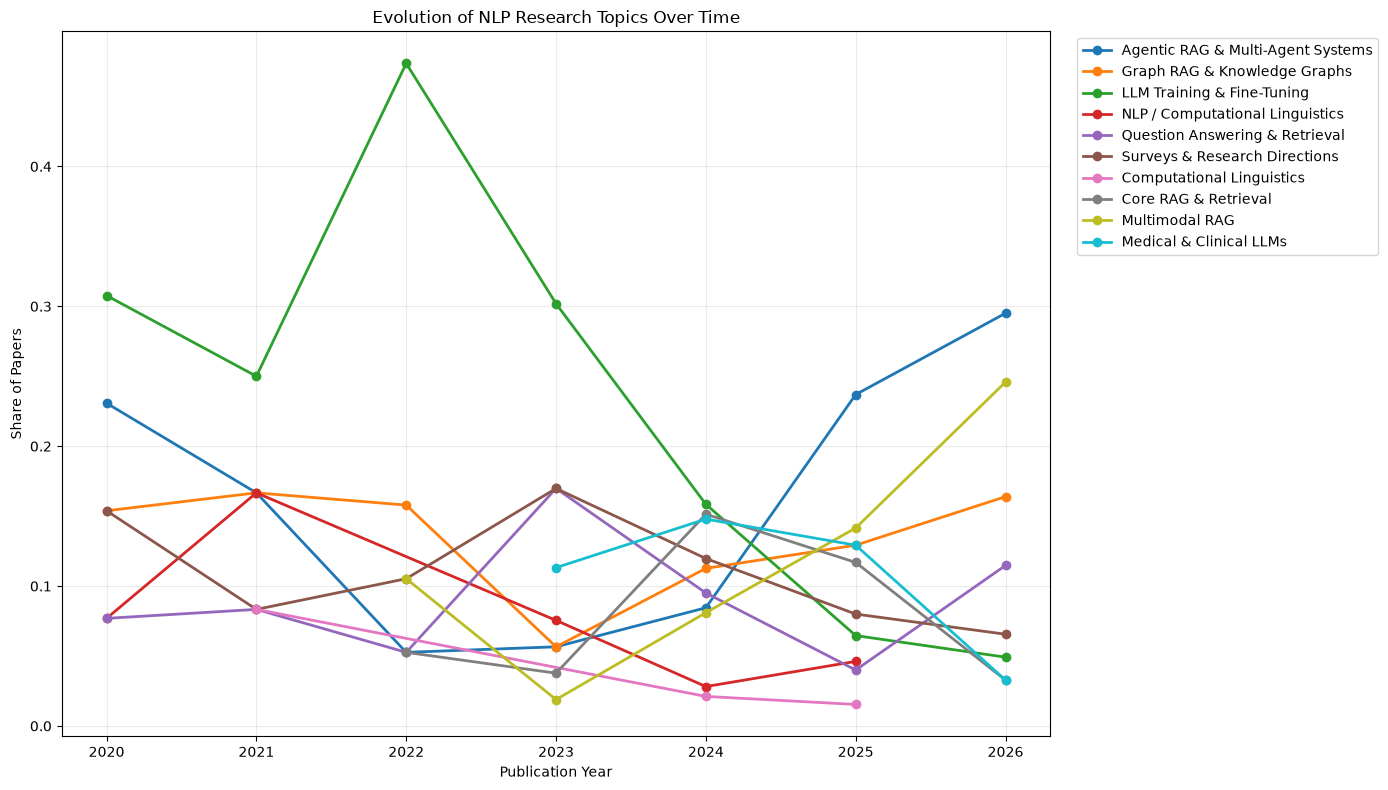

In [63]:
# Topic evolution over time

plt.figure(figsize=(14, 8))

for topic in topic_year_counts["topic_name"].unique():
    topic_data = topic_year_counts[
        topic_year_counts["topic_name"] == topic
    ].sort_values("year")

    plt.plot(
        topic_data["year"],
        topic_data["topic_share"],
        marker="o",
        linewidth=2,
        label=topic
    )

plt.xlabel("Publication Year")
plt.ylabel("Share of Papers")
plt.title("Evolution of NLP Research Topics Over Time")

plt.xticks(sorted(topic_year_counts["year"].unique()))
plt.grid(alpha=0.25)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [65]:
# Semantic similarity between NLP topics

from sklearn.metrics.pairwise import cosine_similarity

# Load saved paper embeddings
embeddings = np.load(
    "../data/processed/paper_embeddings.npy"
)

print("Embedding matrix:", embeddings.shape)

# Average embedding for each NLP topic
topic_embeddings = []

topic_ids = sorted(papers_nlp["topic_id"].unique())

for topic_id in topic_ids:
    topic_mask = papers_nlp["topic_id"] == topic_id
    indices = np.where(topic_mask.to_numpy())[0]

    topic_mean = embeddings[indices].mean(axis=0)
    topic_mean = topic_mean / np.linalg.norm(topic_mean)

    topic_embeddings.append(topic_mean)

topic_embeddings = np.vstack(topic_embeddings)

# Pairwise cosine similarity between topic representations
topic_similarity = cosine_similarity(topic_embeddings)

topic_similarity_df = pd.DataFrame(
    topic_similarity,
    index=[topic_labels[i] for i in topic_ids],
    columns=[topic_labels[i] for i in topic_ids]
)

print("\nTopic semantic similarity matrix:")
print(topic_similarity_df.round(3))

Embedding matrix: (767, 384)

Topic semantic similarity matrix:
                                   Core RAG & Retrieval  \
Core RAG & Retrieval                              1.000   
Computational Linguistics                         0.801   
Surveys & Research Directions                     0.931   
Agentic RAG & Multi-Agent Systems                 0.848   
Multimodal RAG                                    0.806   
NLP / Computational Linguistics                   0.812   
Medical & Clinical LLMs                           0.833   
Graph RAG & Knowledge Graphs                      0.866   
LLM Training & Fine-Tuning                        0.943   
Question Answering & Retrieval                    0.938   

                                   Computational Linguistics  \
Core RAG & Retrieval                                   0.801   
Computational Linguistics                              1.000   
Surveys & Research Directions                          0.819   
Agentic RAG & Multi-Agent Syst

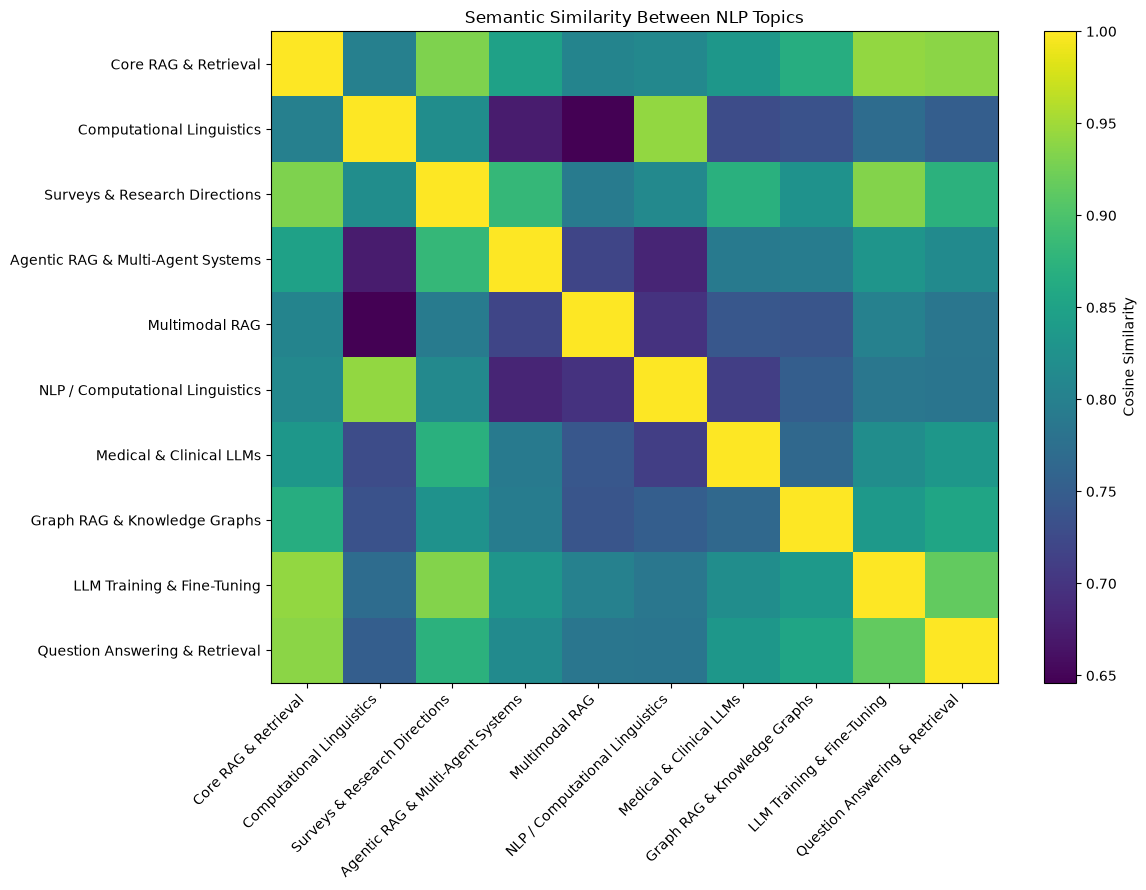

In [66]:
# Visualize semantic similarity between NLP topics

plt.figure(figsize=(12, 9))

plt.imshow(
    topic_similarity,
    aspect="auto"
)

plt.colorbar(label="Cosine Similarity")

plt.xticks(
    range(len(topic_ids)),
    [topic_labels[i] for i in topic_ids],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(topic_ids)),
    [topic_labels[i] for i in topic_ids]
)

plt.title("Semantic Similarity Between NLP Topics")
plt.tight_layout()
plt.show()

In [67]:
# Save final NLP and research-analysis outputs

output_dir = "../data/processed"

# 1. NLP topic assignments
papers_nlp[
    [
        "paper_id",
        "title",
        "year",
        "citation_count",
        "topic_id"
    ]
].assign(
    topic_name=lambda df: df["topic_id"].map(topic_labels)
).to_parquet(
    f"{output_dir}/nlp_topic_assignments.parquet",
    index=False
)

# 2. Topic coherence
coherence_df.to_parquet(
    f"{output_dir}/topic_coherence.parquet",
    index=False
)

# 3. Topic semantic similarity
topic_similarity_df.to_parquet(
    f"{output_dir}/topic_semantic_similarity.parquet"
)

# 4. Topic-year prevalence
topic_year_counts.to_parquet(
    f"{output_dir}/topic_year_prevalence.parquet",
    index=False
)

# 5. Topic-community alignment
topic_alignment.to_parquet(
    f"{output_dir}/topic_community_alignment.parquet",
    index=False
)

# 6. Integrated research dataset
integrated_df.to_parquet(
    f"{output_dir}/research_analysis_dataset.parquet",
    index=False
)

print("Final analysis outputs saved successfully.")

Final analysis outputs saved successfully.
